# Antecedent rainfall with stage-specific basal drainage

Apply 0, 100, 250, 500, 750, or 1000 mm over 90 days, then the same triggering event of 4.5 mm/h for 24 h. Compare sufficient antecedent drainage with capacity just below the antecedent input to see which state is carried into the event.

Maximum column depth is 1.00 m. The requested initial water table is 1.30 m, below the finite base, so the solver initializes the effective water table at 1.00 m with zero initial water-column height. Factor of safety (FS) is extracted at the base, 1.00 m; complete hydraulic and stability profiles are also returned. See [column geometry and finite-base rules](/unsatstab/fundamentals/#geometry-and-initial-water-table).

Event time zero is the trigger start; it does not reset moisture or retained water. See [antecedent time references](/unsatstab/fundamentals/#finite-antecedent-infiltration-history). This notebook explicitly uses `equation_set="baum_etal"` as its comparison baseline; the package default is `"srivastava_yeh"`. Changing that setting and rerunning the cells can alter the outcomes. See the [equation comparison](/unsatstab/fundamentals/#pressure-and-water-content-equation-sets).


## Rainfall history and drainage settings

The background infiltration before the 90-day window is zero. Antecedent rainfall is a separate history; 500 mm over 90 days corresponds to 0.23148 mm/h. Here saturated conductivity is $K_{\mathrm{s}}=36$ mm/h and slope angle is $\delta=40^\circ$.

For this column, drainage capacity is $14.87433\eta$ mm/h, where $\eta$ is drainage efficiency. The first experiment sets antecedent efficiency to 1 and event efficiency to 0.015:

| Stage | Efficiency | Capacity [mm/h] |
| --- | ---: | ---: |
| Antecedent | 1.0 | 14.87433 |
| Triggering event | 0.015 | 0.22311 |

The first capacity exceeds all antecedent input rates in this sweep. The second is just below the 500 mm / 90-day rate. Capacities are upper limits, not actual outflows or fractions of rain. The efficiency change is prescribed; rainfall does not automatically change the drainage setting. See [drainage capacity](/unsatstab/fundamentals/#basal-transfer-and-drainage-capacity).

Supply amount and duration with `AntecedentRainfall.uniform(...)`; for a measured hyetograph, wrap its `RainfallSeries` in `AntecedentRainfall`. Leaving `drainage_efficiency=None` uses the event boundary throughout both stages. The [input guide](/unsatstab/inputs-outputs/#antecedent-rainfall) gives both forms.

The first table summarizes the state at event start and the sampled threshold crossing. The second reports water-balance diagnostics. Profile water already includes the saturation associated with basal storage, so those quantities cannot be added as independent stores. See [antecedent water-balance checks](/unsatstab/verification/#antecedent-water-balance-checks) for the residual definition and interpretation.


In [8]:
%matplotlib inline
import matplotlib as mpl
import matplotlib.pyplot as plt
import numpy as np
import tol_colors as tc
from IPython.display import display
import pandas as pd
import unsatstab as us

mpl.rcParams.update({
    "font.family": "DejaVu Serif",
    "font.serif": ["DejaVu Serif"],
    "font.size": 8.5,
    "mathtext.fontset": "dejavuserif",
    "axes.titlesize": 9,
    "axes.labelsize": 8.5,
    "axes.linewidth": 1.5,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.unicode_minus": False,
    "axes.grid": False,
    "xtick.labelsize": 7.5,
    "ytick.labelsize": 7.5,
    "legend.fontsize": 7.5,
    "legend.frameon": False,
    "xtick.major.width": 1.5,
    "ytick.major.width": 1.5,
})
COLORS = tc.colorsets["high_contrast"]
TIME_CMAP = tc.colormaps["rainbow_PuBr"]



In [9]:
hydro = us.HydraulicProperties(
    equation_set="baum_etal",
    slope_angle_deg=40.0,
    maximum_depth=1.30,
    initial_water_table_depth=1.30,
    saturated_hydraulic_conductivity=1.0e-5,
    alpha=3.0,
    theta_s=0.41,
    theta_r=0.06,
    long_term_infiltration=0.0,  # equilibrium BEFORE the antecedent window
    n_roots=120,
    n_depths=120,
)
rainfall = us.RainfallSeries.constant(4.5, 24.0)
strength = us.StrengthProperties(3000.0, 33.6, 18000.0)
boundary = us.FinitePerchedBoundary(drainage_efficiency=0.015)
output_times_h = np.arange(97, dtype=float) * (15.0 / 60.0)  # convert minutes to hours
antecedent_days = 90.0
antecedent_efficiency = 1.0  # capacity suffices for this moderate rainfall sweep
antecedent_cases_mm = [0.0, 100.0, 250.0, 500.0, 750.0, 1000.0]
results = {
    total_mm: us.run_single_column(
        hydro=hydro,
        rainfall=rainfall,
        strength=strength,
        boundary=boundary,
        depth_to_failure_plane=1.0,
        output_times=output_times_h,
        antecedent=us.AntecedentRainfall.uniform(
            total_rainfall_mm=total_mm,
            duration=antecedent_days, duration_units="days",  # explicit day input; stored as hours
            drainage_efficiency=antecedent_efficiency,
        ),
        storage_time_step=1.0,
    )
    for total_mm in antecedent_cases_mm
}

selected_depth_m = results[500.0].metadata["failure_plane_depth_m"]
effective_initial_depth = results[500.0].metadata["initial_water_table_depth_m"]

# The combined forcing is also available for ordinary or spatial runs.
antecedent_example = us.AntecedentRainfall.uniform(500.0, antecedent_days, drainage_efficiency=antecedent_efficiency, duration_units="days")
history = antecedent_example.prepend_to(rainfall)
print(f"Antecedent rainfall: {history.fluxes[0] * 3.6e6:.5f} mm/h")  # convert m/s to mm/h
print(f"Antecedent drainage capacity: {results[500.0].metadata['antecedent_drainage_capacity_m_s'] * 3.6e6:.5f} mm/h")  # convert m/s to mm/h
print(f"Event drainage capacity: {boundary.drainage_capacity(hydro) * 3.6e6:.5f} mm/h")  # convert m/s to mm/h


Antecedent rainfall: 0.23148 mm/h
Antecedent drainage capacity: 14.87433 mm/h
Event drainage capacity: 0.22311 mm/h


In [10]:
rows = []
for total_mm, result in results.items():
    failure = np.flatnonzero(result.factor_of_safety_at_failure_plane <= 1.0)
    first_h = result.time[failure[0]] if len(failure) else np.nan
    rows.append({
        "antecedent_rainfall_mm": total_mm,
        "antecedent_rate_mm_h": total_mm / (antecedent_days * 24),  # convert days to hours
        "additional_profile_water_mm": result.metadata["antecedent_profile_water_change_mm"],
        "event_initial_surface_K_mm_h": result.profiles[0]["hydraulic_conductivity"][0] * 3.6e6,  # convert m/s to mm/h
        "event_initial_surface_theta": result.profiles[0]["volumetric_water_content"][0],
        "event_initial_water_table_depth_m": result.water_table_depth[0],
        "event_initial_FS": result.factor_of_safety_at_failure_plane[0],
        "first_sampled_failure_h": first_h,
        "trigger_rainfall_to_failure_mm": 4.5 * first_h,
    })
display(pd.DataFrame(rows))

budget_rows = [{
    "antecedent_rainfall_mm": total_mm,
    "effective_infiltration_mm": result.metadata["antecedent_effective_infiltration_mm"],
    "discarded_rainfall_mm": result.metadata["antecedent_rainfall_excess_mm"],
    "profile_water_change_mm": result.metadata["antecedent_profile_water_change_mm"],
    "basal_storage_mm": result.metadata["antecedent_basal_storage_mm"],
    "basal_drainage_mm": result.metadata["antecedent_drainage_mm"],
    "balance_residual_mm": result.metadata["antecedent_water_balance_residual_mm"],
} for total_mm, result in results.items()]
display(pd.DataFrame(budget_rows))
# These are scenario checks: efficient drainage does not impose fixed water table generally.
assert all(result.water_table_depth[0] == effective_initial_depth for result in results.values())
assert all(result.cumulative_excess[0] == 0.0 for result in results.values())
# FS <= 1 at event time zero means antecedent conditions already reach the
# modeled failure threshold; it must not be attributed to the triggering storm.


,antecedent_rainfall_mm,antecedent_rate_mm_h,additional_profile_water_mm,event_initial_surface_K_mm_h,event_initial_surface_theta,event_initial_water_table_depth_m,event_initial_FS,first_sampled_failure_h,trigger_rainfall_to_failure_mm
0,0.0,0.000000,0.000000,3.650649,0.120628,1.3,1.243046,21.50,96.750
1,100.0,0.046296,0.381243,3.692251,0.121156,1.3,1.242932,21.50,96.750
2,250.0,0.115741,0.952247,3.754653,0.121947,1.3,1.242761,21.25,95.625
3,500.0,0.231481,1.901659,3.858657,0.123257,1.3,1.242476,21.00,94.500
4,750.0,0.347222,2.848295,3.962661,0.124559,1.3,1.242190,21.00,94.500
5,1000.0,0.462963,3.792211,4.066664,0.125853,1.3,1.241903,20.75,93.375


,antecedent_rainfall_mm,effective_infiltration_mm,discarded_rainfall_mm,profile_water_change_mm,basal_storage_mm,basal_drainage_mm,balance_residual_mm
0,0.0,0.0,0.0,0.000000,0.0,0.000000,0.000000
1,100.0,100.0,0.0,0.381243,0.0,99.644611,-0.025854
2,250.0,250.0,0.0,0.952247,0.0,249.111527,-0.063775
3,500.0,500.0,0.0,1.901659,0.0,498.223055,-0.124714
4,750.0,750.0,0.0,2.848295,0.0,747.334582,-0.182877
5,1000.0,1000.0,0.0,3.792211,0.0,996.446110,-0.238321


## Profiles under sufficient antecedent drainage

All event-start water-table depths remain 1.00 m, with zero retained basal storage, because antecedent capacity exceeds these input rates. Surface moisture nevertheless changes: between 0 and 1000 mm, event-start water content increases from 0.1509 to 0.1551 m³/m³ and conductivity from 6.191 to 6.574 mm/h.

The selected plane remains at the water table at trigger start. Its pressure is zero, so initial FS is the same (1.130) in all cases. Wetness changes above that plane do not directly supply a suction contribution at the saturated base.

For 500 mm / 90 days, about 498.81 mm drains and 1.18 mm remains as additional profile water, with a residual of +0.007 mm. These are computed quantities, not prescribed fractions of rainfall.

The first sampled FS ≤ 1 is 8.75 h for 0–500 mm, 8.50 h for 750 mm, and 8.25 h for 1000 mm. The wettest case advances the sampled crossing by 30 minutes. The 15-minute output spacing limits that comparison; changing rainfall timing could also change it.

With sufficient antecedent drainage, the main inherited difference is moisture rather than initial water-table rise. The next experiment allows accumulation before the trigger.


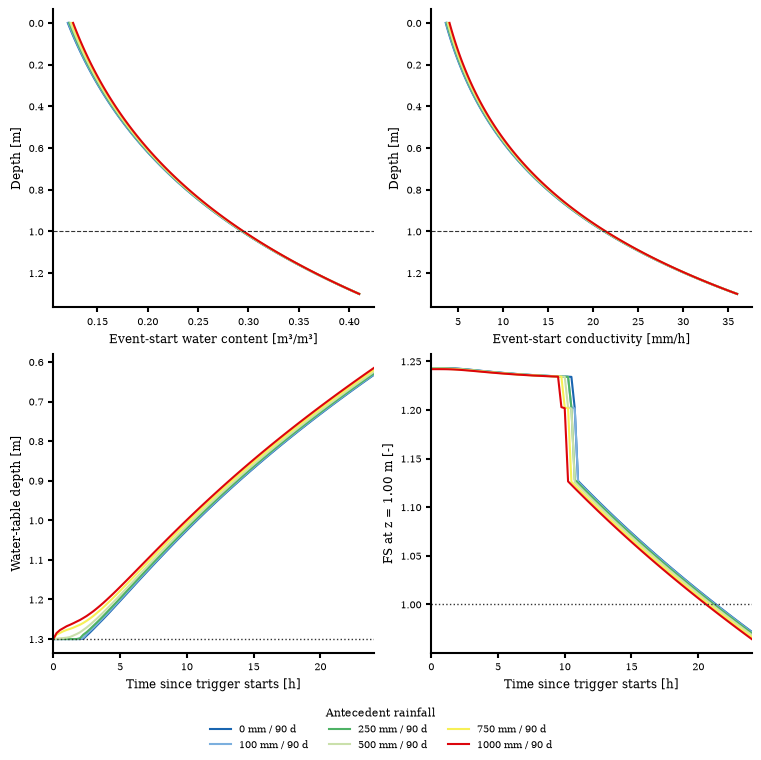

In [12]:
fig, axes = plt.subplots(2, 2, figsize=(7.5, 7.5), constrained_layout=True)
colors = tc.rainbow_discrete(len(results)).colors
for color, (total_mm, result) in zip(colors, results.items()):
    time_h = result.time
    label = f"{total_mm:.0f} mm / 90 d"
    initial = result.profiles[0]
    axes[0, 0].plot(initial["volumetric_water_content"], initial["z"], color=color, label=label)
    axes[0, 1].plot(initial["hydraulic_conductivity"] * 3.6e6, initial["z"], color=color)  # convert m/s to mm/h
    axes[1, 0].plot(time_h, result.water_table_depth, color=color)
    axes[1, 1].plot(time_h, result.factor_of_safety_at_failure_plane, color=color)
axes[0, 0].set(xlabel="Event-start water content [m³/m³]", ylabel="Depth [m]")
axes[0, 1].set(xlabel="Event-start conductivity [mm/h]", ylabel="Depth [m]")
for ax in axes[0]:
    ax.invert_yaxis()
    ax.axhline(selected_depth_m, color="0.2", linestyle="--", linewidth=0.8)
axes[1, 0].set(xlabel="Time since trigger starts [h]", ylabel="Water-table depth [m]", xlim=(0, 24))
axes[1, 0].axhline(effective_initial_depth, color="0.2", linestyle=":", linewidth=1.0)
axes[1, 0].invert_yaxis()
axes[1, 1].set(xlabel="Time since trigger starts [h]", ylabel=f"FS at z = {selected_depth_m:.2f} m [-]", xlim=(0, 24))
axes[1, 1].axhline(1.0, color="0.2", linestyle=":", linewidth=1.0)
handles, labels = axes[0, 0].get_legend_handles_labels()
fig.legend(handles, labels, loc="outside lower center", ncol=3, title="Antecedent rainfall", title_fontsize=8.)#, labelspacing=0.3, handlelength=1.5)
plt.show()


## Antecedent capacity just below the infiltration rate

Keep the soil, geometry, triggering event, and 90-day amounts unchanged. For each amount, set antecedent capacity to 95% of its uniform effective infiltration rate $I_{\mathrm{a}}$:

$$
\eta_{\mathrm{equal}}=\frac{I_{\mathrm{a}}}{K_{\mathrm{s}}\sin^2\delta},
\qquad \eta_{\mathrm{a}}=0.95\eta_{\mathrm{equal}}.
$$

Here $\eta_{\mathrm{equal}}$ is the efficiency that makes capacity equal to this input, and $\eta_{\mathrm{a}}$ is the selected antecedent efficiency. This is an inversion of the [capacity formula](/unsatstab/fundamentals/#basal-transfer-and-drainage-capacity), not a fitted soil law. The 0.95 multiplier is a sensitivity choice; actual retained water is not exactly 5% of rainfall because basal transfer responds progressively.

The code prints exact equality for 500 mm as a reference, then uses 95% in the sweep. Event efficiency remains 0.015. Because antecedent efficiency varies with amount, this experiment changes both rainfall and boundary setting. Interpret the differences as responses to the combined rainfall and drainage assumptions, rather than rainfall amount alone.


In [5]:
matching_capacity_fraction = 0.95  # capacity is intentionally below the sustained input
reference_antecedent = us.AntecedentRainfall.uniform(500.0, antecedent_days, duration_units="days")
reference_infiltration = min(
    reference_antecedent.rainfall.fluxes[0],
    hydro.saturated_hydraulic_conductivity,
)
unit_capacity = us.FinitePerchedBoundary(drainage_efficiency=1.0).drainage_capacity(hydro)
reference_eta_equal = reference_infiltration / unit_capacity
print(f"Reference antecedent rainfall: {reference_antecedent.rainfall.fluxes[0] * 3.6e6:.5f} mm/h")  # convert m/s to mm/h
print(f"Efficiency for exact capacity equality: {reference_eta_equal:.10f}")
print(f"Selected capacity / infiltration ratio: {matching_capacity_fraction:.2f}")


Reference antecedent rainfall: 0.23148 mm/h
Efficiency for exact capacity equality: 0.0155624783
Selected capacity / infiltration ratio: 0.95


In [6]:
matched_results = {}
matching_rows = []
for total_mm in antecedent_cases_mm:
    previous_rain = us.AntecedentRainfall.uniform(total_mm, antecedent_days, duration_units="days")
    effective_rate = min(previous_rain.rainfall.fluxes[0], hydro.saturated_hydraulic_conductivity)
    eta_equal = effective_rate / unit_capacity
    matched_efficiency = matching_capacity_fraction * eta_equal
    if not 0.0 <= matched_efficiency <= 1.0:
        raise ValueError("The requested antecedent capacity exceeds the allowed efficiency range.")
    result = us.run_single_column(
        hydro=hydro,
        rainfall=rainfall,
        strength=strength,
        boundary=boundary,
        depth_to_failure_plane=selected_depth_m,
        output_times=output_times_h,
        antecedent=us.AntecedentRainfall.uniform(
            total_rainfall_mm=total_mm,
            duration=antecedent_days, duration_units="days",  # explicit day input; stored as hours
            drainage_efficiency=matched_efficiency,
        ),
        storage_time_step=1.0,
    )
    matched_results[total_mm] = result
    initial = result.profiles[0]
    z_plane = selected_depth_m
    failure = np.flatnonzero(result.factor_of_safety_at_failure_plane <= 1.0)
    matching_rows.append({
        "antecedent_rainfall_mm": total_mm,
        "effective_infiltration_mm_h": effective_rate * 3.6e6,  # convert m/s to mm/h
        "eta_equal": eta_equal,
        "antecedent_efficiency": matched_efficiency,
        "actual_capacity_mm_h": result.metadata["antecedent_drainage_capacity_m_s"] * 3.6e6,  # convert m/s to mm/h
        "basal_storage_mm": result.metadata["antecedent_basal_storage_mm"],
        "event_initial_water_table_m": result.water_table_depth[0],
        "failure_plane_below_water_table": bool(z_plane >= result.water_table_depth[0]),
        "plane_raw_unsaturated_head_m": np.interp(z_plane, initial["z"], initial["pressure_head_unsaturated"]),
        "plane_total_head_m": result.pressure_head_at_failure_plane[0],
        "plane_water_content": np.interp(z_plane, initial["z"], initial["volumetric_water_content"]),
        "event_initial_FS": result.factor_of_safety_at_failure_plane[0],
        "first_sampled_failure_h": result.time[failure[0]] if len(failure) else np.nan,
        "balance_residual_mm": result.metadata["antecedent_water_balance_residual_mm"],
    })
matching_table = pd.DataFrame(matching_rows)
display(matching_table[[
    "antecedent_rainfall_mm", "antecedent_efficiency", "actual_capacity_mm_h",
    "basal_storage_mm", "event_initial_water_table_m", "event_initial_FS", "first_sampled_failure_h",
]])
# Diagnostics at the fixed failure-plane depth explain the initial FS change.
display(matching_table[[
    "antecedent_rainfall_mm", "event_initial_water_table_m", "failure_plane_below_water_table",
    "plane_raw_unsaturated_head_m", "plane_total_head_m", "plane_water_content",
]])


,antecedent_rainfall_mm,antecedent_efficiency,actual_capacity_mm_h,basal_storage_mm,event_initial_water_table_m,event_initial_FS,first_sampled_failure_h
0,0.0,0.000000,0.000000,0.000000,1.300000,1.243046,21.50
1,100.0,0.002957,0.043981,4.946106,1.150303,1.242932,20.25
2,250.0,0.007392,0.109954,12.365265,1.058301,1.242761,18.25
3,500.0,0.014784,0.219907,24.730529,0.949658,1.108569,15.25
4,750.0,0.022177,0.329861,37.095794,0.862367,1.070900,11.75
5,1000.0,0.029569,0.439815,49.461059,0.785867,1.037886,8.00


,antecedent_rainfall_mm,event_initial_water_table_m,failure_plane_below_water_table,plane_raw_unsaturated_head_m,plane_total_head_m,plane_water_content
0,0.0,1.300000,False,-0.229813,-0.229813,0.293545
1,100.0,1.150303,False,-0.229424,-0.229424,0.293705
2,250.0,1.058301,False,-0.228841,-0.228841,0.293945
3,500.0,0.949658,True,-0.227871,0.029542,0.410000
4,750.0,0.862367,True,-0.226903,0.080766,0.410000
5,1000.0,0.785867,True,-0.225937,0.125659,0.410000


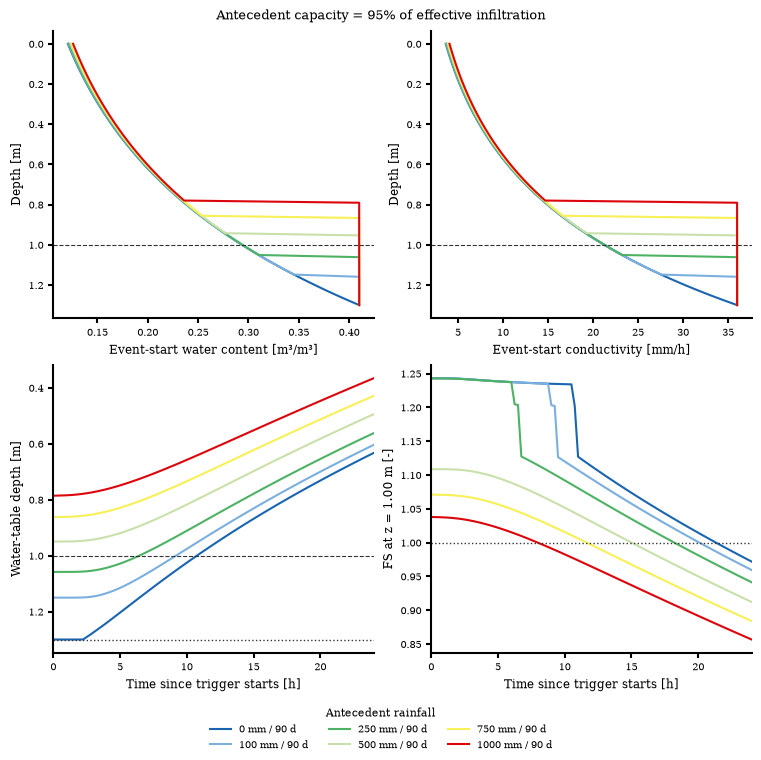

In [ ]:
fig, axes = plt.subplots(2, 2, figsize=(7.5, 7.5), constrained_layout=True)
colors = tc.rainbow_discrete(len(matched_results)).colors
for color, (total_mm, result) in zip(colors, matched_results.items()):
    time_h = result.time
    label = f"{total_mm:.0f} mm / 90 d"
    initial = result.profiles[0]
    axes[0, 0].plot(initial["volumetric_water_content"], initial["z"], color=color, label=label)
    axes[0, 1].plot(initial["hydraulic_conductivity"] * 3.6e6, initial["z"], color=color)  # convert m/s to mm/h
    axes[1, 0].plot(time_h, result.water_table_depth, color=color)
    axes[1, 1].plot(time_h, result.factor_of_safety_at_failure_plane, color=color)
axes[0, 0].set(xlabel="Event-start water content [m³/m³]", ylabel="Depth [m]")
axes[0, 1].set(xlabel="Event-start conductivity [mm/h]", ylabel="Depth [m]")
for ax in axes[0]:
    ax.invert_yaxis()
    ax.axhline(selected_depth_m, color="0.2", linestyle="--", linewidth=0.8)
axes[1, 0].set(xlabel="Time since trigger starts [h]", ylabel="Water-table depth [m]", xlim=(0, 24))
axes[1, 0].axhline(selected_depth_m, color="0.2", linestyle="--", linewidth=0.8)
axes[1, 0].invert_yaxis()
axes[1, 1].set(xlabel="Time since trigger starts [h]", ylabel=f"FS at z = {selected_depth_m:.2f} m [-]", xlim=(0, 24))
axes[1, 1].axhline(1.0, color="0.2", linestyle=":", linewidth=1.0)
handles, labels = axes[0, 0].get_legend_handles_labels()
fig.legend(handles, labels, loc="outside lower center", ncol=3, title="Antecedent rainfall", title_fontsize=8.)#, labelspacing=0.3, handlelength=1.5)
fig.suptitle(f"Antecedent capacity = {matching_capacity_fraction:.0%} of effective infiltration", fontsize=9)
plt.show()


### Results at 95% capacity

The small capacity deficit accumulates over the 90-day history. Retained basal water at 250 and 500 mm is about 12.41 and 24.81 mm. That storage raises the water table before the trigger and increases positive pressure at the base.

| Antecedent rain [mm / 90 d] | Antecedent efficiency | Event-start water-table depth [m] | Event-start FS at the base | First sampled FS ≤ 1 [h] |
| ---: | ---: | ---: | ---: | ---: |
| 0 | 0.000000 | 1.000 | 1.130 | 8.75 |
| 100 | 0.002957 | 0.850 | 1.066 | 7.50 |
| 250 | 0.007392 | 0.758 | 1.026 | 5.00 |
| 500 | 0.014784 | 0.649 | 0.979 | 0.00 |
| 750 | 0.022177 | 0.562 | 0.941 | 0.00 |
| 1000 | 0.029569 | 0.485 | 0.908 | 0.00 |

The 0, 100, and 250 mm cases start above the stability threshold (FS > 1), but the 500, 750, and 1000 mm cases already have FS ≤ 1 at event start. A reported crossing at zero means the antecedent state has reached the modeled threshold; it does not locate when that happened during the previous 90 days. Only triggering-event profiles are returned here.

At 250 mm, the event-start water table is 0.758 m and pressure head at the base is 0.142 m, giving FS 1.026. At 500 mm, water-table depth is 0.649 m and head is 0.206 m, giving FS 0.979. The selected plane is saturated throughout this comparison: the FS reduction comes from increasing positive pressure, not a switch from suction to saturation at that plane.

The diagnostic table contrasts raw fixed-domain head with reconstructed head. Raw head at the initial base stays zero; the moving-water table reconstruction supplies the positive pressure there. See [pressure assumptions](/unsatstab/fundamentals/#basal-and-pressure-assumptions) for that approximation. Because the selected antecedent efficiency changes with rainfall amount, this is a joint rainfall/capacity sensitivity experiment rather than increasingly wet histories under a single unchanged boundary.


## Interpretation and computational scope

The experiments distinguish reduced suction under sufficient drainage from water-table rise under restricted drainage. Rainfall amount alone does not determine the field groundwater state: its time distribution, initial conditions, material properties, and boundary setting matter.

Times are relative to the trigger, while water-table rise and retained storage reference the beginning of the complete history. FS at or below 1 at event zero indicates that the modeled threshold was already reached before the trigger; these event-only outputs do not locate its first antecedent crossing. Threshold times here are sampled every 15 minutes.

For an application, supply a measured rainfall history where available, justify any efficiency change between stages, and check [numerical convergence](/unsatstab/inputs-outputs/#numerical-controls). Use the [water-balance diagnostics](/unsatstab/verification/#antecedent-water-balance-checks) to identify large reconstruction errors or storage above pore capacity. The [antecedent-history assumptions](/unsatstab/fundamentals/#finite-antecedent-infiltration-history) and [pressure reconstruction limits](/unsatstab/fundamentals/#basal-and-pressure-assumptions) apply throughout.
